# Tutorial de Ciencia de Datos (UdeSA) 2026

## Tutorial 10

### Ridge y Lasso

**Objetivo:**  
Que se familiaricen con las técnicas de Regularización de Ridge y Lasso

### Temario:
- Regularización con Ridge
- Regularización con Lasso
- Ejemplo con la base de hitters

### Modelos lineales regularizados con Ridge y Lasso

Exploraremos brevemente el conjunto de datos "Hitters" y usaremos la librería de sklearn para ajustar modelos lineales regularizados por Ridge y Lasso (son las siglas en inglés para: operador de selección y contracción mínima absoluta) con el fin de predecir el salario de los jugadores de béisbol.

Esta es una adaptación del Lab de Linear Models and Regularization Methods del libro "Introduction to Statistical Learning with Applications in Python" de Gareth James, Daniela Witten, Trevor Hastie, Robert Tibshirani y Jonathan Taylor. [Acá](https://islp.readthedocs.io/en/latest/labs/Ch06-varselect-lab.html) pueden encontrar más información.

##### Baseball data, 'Hitters'
Datos de la Major League de Baseball Data en las temporadas 1986 y 1987.
La base de Hitters tiene las siguientes variables:
- AtBat: Number of times at bat in 1986
- Hits: Number of hits in 1986
- HmRun: Number of home runs in 1986
- Runs: Number of runs in 1986
- RBI: Number of runs batted in in 1986
- Walks: Number of walks in 1986
- Years: Number of years in the major leagues
- CAtBat: Number of times at bat during his career
- CHits: Number of hits during his career
- CHmRun: Number of home runs during his career
- CRuns: Number of runs during his career
- CRBI: Number of runs batted in during his career
- CWalks: Number of walks during his career
- League: A factor with levels A and N indicating player’s league at the end of 1986
- Division: A factor with levels E and W indicating player’s division at the end of 1986
- PutOuts: Number of put outs in 1986
- Assists: Number of assists in 1986
- Errors: Number of errors in 1986
- Salary: 1987 annual salary on opening day in thousands of dollars
- NewLeague: A factor with levels A and N indicating player’s league at the beginning of 1987


Nuestro objetivo será **predecir el salario** (regresión)

### 1. Leer el conjunto de datos y explorar la estructura de datos

In [ ]:
# Importamos los paquetes necesarios
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from ISLP import load_data

from sklearn.preprocessing import scale
from sklearn.linear_model import Lasso, LassoCV, Ridge, RidgeCV, ElasticNet, ElasticNetCV
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

In [ ]:
Hitters = load_data('Hitters')
print(Hitters.info())
print('Dimensión de la base:', Hitters.shape, '\n')
#Vemos los missing values en Y
print('\nMissings en variable dependiente (Y):', np.isnan(Hitters['Salary']).sum())

In [ ]:
# Eliminamos missings en la variable dependiente
Hitters = Hitters.dropna()
print('\n Nueva dimensión de la base:', Hitters.shape)

In [ ]:
Hitters

In [ ]:
Hitters.describe().T

### 2. Preparar las X e Y que usaremos en el modelo

Aquí seleccionamos las variables que utilizaremos en nuestro modelo y transformamos a dummies las que son strings

In [ ]:
y = Hitters.Salary

In [ ]:
print(Hitters.League.value_counts())
print(Hitters.Division.value_counts())
print(Hitters.NewLeague.value_counts())

# Creamos variables dummies para las variables categóricas para poder usarlas en la regresión
dummies = pd.get_dummies(Hitters[['League', 'Division', 'NewLeague']], drop_first=True)
dummies

In [ ]:
# Definimos las variables que incluiremos en el set de X

# Eliminamos salarios (porque es nuestra y) y las columnas categóricas (solo dejamos las dummies)
X_ = Hitters.drop(['Salary', 'League', 'Division', 'NewLeague'], axis=1).astype('float64')
X = pd.concat([X_, dummies[['League_N', 'Division_W', 'NewLeague_N']]], axis=1)
X.info()

### 3. Dividimos la base en observaciones para entrenamiento y testeo

Ahora dividimos la muestra en un conjunto de entrenamiento y un conjunto de prueba para luego estimar el error en el conjunto de prueba.

In [ ]:
# Train test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=100)

# Revisamos cuantas observaciones quedaron para Test y cuantas para Entrenamiento.
print(f'El conjunto de entrenamiento tiene {len(X_train)} observaciones.')
print(f'El conjunto de test tiene {len(X_test)} observaciones.')

### 4. Regularización


Les dejamos la documentación para que puedan comparar:
- Para clasificación ($Y$ categorica) recuerden que usamos la función [LogisticRegression()](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html). Con dicha función, se puede hacer un ejercicio de clasificacion con amabas penalidades. Lasso usa una penalidad llamada l1 (que fuerza algunos coeficientes para que sean iguales a 0, seleccionando variables) y Ridge usa una penalidad llamada l2 (que hace que algunos coeficientes sean más cercanos a 0 pero sin llegar a 0)
- Para regresión ($Y$ numerica)  usaremos la funciones [Ridge()](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html#sklearn.linear_model.Ridge) y [Lasso()](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html#sklearn.linear_model.Lasso)


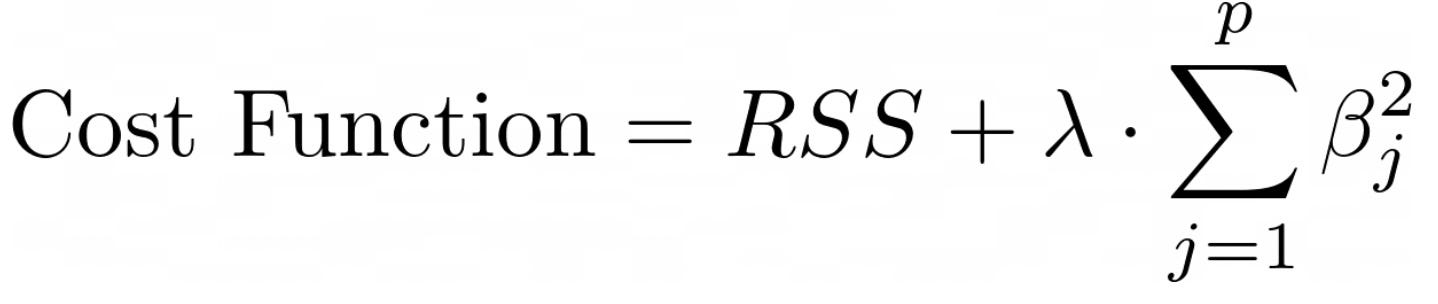

Usamos la funciones [Ridge()](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html) y [Lasso()](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html) para realizar distintas regresiones lineales regularizadas. Estas funciones tienen un argumento  **alfa** $\alpha$ (es el **λ** pero con otro nombre) que **controla el peso de la regularización**.

In [ ]:
from sklearn.preprocessing import StandardScaler

# Estadisticas antes de estandarizar
X_train.describe().T

In [ ]:
# Iniciamos el Standard Scaler
sc = StandardScaler()

# Estandarizamos las observaciones de entrenamiento
X_train_transformed = pd.DataFrame(sc.fit_transform(X_train), index=X_train.index, columns=X_train.columns)

# Estandarizamos las observaciones de test
X_test_transformed = pd.DataFrame(sc.transform(X_test), index=X_test.index, columns=X_test.columns)

# Estadisticas de los predictores luego de estandarizar
X_train_transformed.describe().T

### 5. Regresión con Ridge

Recordemos que el objetivo de la regresión linear es minimizar la Suma de los Cuadrados de los Residuos (o RSS, por su siglas en ingles):

$$ RSS = \sum_{i=1}^{n}(y_i - \hat{y_i})^2  $$


La regulación con ridge (o L2) agrega una mayor penalidad a esta suma con el objetivo de que los coeficientes individuales no se vuelvan muy grandes:

$$ \text{Función de Costo} = \sum_{i=1}^{n}(y_i - \hat{y_i})^2 + λ \cdot \sum_{j=1}^{p}β_j^2   $$

De esta forma λ es el parametro de regularización, que determina que tan grande es la influencia de la regularización. La segunda sumatoria contiene la suma de todos los coeficientes al cuadrado.  

Empecemos con un modelo sin shrinkage $\alpha =0$ (lo mismo que λ):

In [ ]:
alpha = 0
print("Alpha/lambda:", alpha)

#creamos el modelo
ridge_a0 = Ridge(alpha = alpha)
#estimamos el modelo
ridge_a0.fit(X_train_transformed, y_train)
pred_a0 = ridge_a0.predict(X_test_transformed)
mse_a0 = mean_squared_error(y_test, pred_a0)

print("Mean Squared Error de testeo (MSE test): ", round(mse_a0,2))
print("Coeficientes del modelo:")
print(pd.Series(ridge_a0.coef_, index = X_train_transformed.columns).round(2))

El $MSE_{test}$ con $\alpha=0$ es: 123,843.3

Probemos elegir arbitrariamente el alpha usando $\alpha=1$:

In [ ]:
alpha = 1
print("Alpha:", alpha)

ridge_a1 = Ridge(alpha = alpha)
ridge_a1.fit(X_train_transformed, y_train)
pred_a1 = ridge_a1.predict(X_test_transformed)
ecm_a1 = mean_squared_error(y_test, pred_a1)

print("Mean Squared Error de testeo (MSE test): ", round(ecm_a1,2))
print("Coeficientes del modelo:")
print(pd.Series(ridge_a1.coef_, index = X_train_transformed.columns).round(2))

El $MSE_{test}$ con $\alpha = 1$ es 117,196.67

Ahora probemos que pasa con un alpha muy grande, por ej. $\alpha=10^{10}$:

In [ ]:
alpha = 10**10
print("Alpha:", alpha)

ridge_a10b = Ridge(alpha)
ridge_a10b.fit(X_train_transformed, y_train)
pred_a10b = ridge_a10b.predict(X_test_transformed)
ecm_a10b = mean_squared_error(y_test, pred_a10b)

print("Mean Squared Error de testeo (MSE test): ", ecm_a10b)
print("Coeficientes del modelo:")
print(pd.Series(ridge_a10b.coef_, index = X_train_transformed.columns).round(10))

#muy cercanos a cero, pero no exactamente cero
#siempre es una combinación de variables, bueno cuando hay mucha multicolinealidad

In [ ]:
pred_a10b
#para todos los jugadores nos predice el mismo salario, la ordenada al origen

El $MSE_{test}$ con $\alpha=10^{10}$ es 238,884.06

Esta gran penalización reduce los coeficientes en un grado muy grande, esencialmente reduciéndose a un modelo que contiene solo el intercepto. Esta contracción excesiva hace que el modelo sea demasiado sesgado, lo que resulta en un ECM más alto.

#### Plot Ridge: coeficientes según parámetros de ajuste alfa

Generaremos una matriz de valores alfa que van desde muy grandes a muy pequeños, esencialmente cubriendo la gama completa de escenarios desde el modelo nulo que contiene solo la intersección, hasta el ajuste de mínimos cuadrados.

Estandarizamos los datos y ajustamos los modelos Lasso para cada valor de alfa.

Ahora veamos la relación entre alfa y los coeficientes, una línea para cada característica.

In [ ]:
# Matriz de valores de alfa
alphas = 10**np.linspace(6,-2,50)*0.5
np.set_printoptions(suppress = True)
alphas

In [ ]:
coefs = []
for a in alphas:
    ridge = Ridge(alpha=a, fit_intercept=False)
    ridge.fit(X_train_transformed, y_train)
    coefs.append(ridge.coef_)

In [ ]:
ax = plt.gca()

ax.plot(alphas, coefs)
ax.set_xscale("log")
plt.xlabel("alpha")
plt.ylabel("Coeficientes")
plt.title("Coeficientes de Ridge como función" "\ndel parametro de regularización")
plt.axis("tight")
plt.show()

#cada línea es el coeficiente de una variable, cuando la penalización es muy pequeña cada uno toma su valor de la regresión multivariada.
#cuando aumenta la penalización, tienden a cero.

En el lado izquierdo casi no hay penalización, por lo que se pueden observar todos los valores que toman los coeficientes de las distintas variables. En los casos donde el α es muy bajo, el sesgo se reduce, pero puede llevar a un overfitting. En el lado derecho podemos ver un modelo mas sencillo con coeficientes muy cercanos a cero. Esto se debe a una penalización muy alta, que puede no ser capaz de reconolecer las estructuras subyacentes de los datos.

Bien, entonces ajustar un modelo de regresión de Ridge con $\alpha = 1$ conduce a un $MSE_{test}$  de prueba más bajo que ajustar un modelo con solo una intersección.

Ahora verificamos si existe algún beneficio al realizar la regresión de Ridge con alpha = 1 en lugar de simplemente realizar la regresión por mínimos cuadrados.

In [ ]:
from sklearn.linear_model import LinearRegression
modelo_lineal = LinearRegression().fit(X_train_transformed, y_train)
pred_lin = modelo_lineal.predict(X_test_transformed)
mse_lin = mean_squared_error(y_test, pred_lin)

print("Mean Squared Error de testeo (MSE test): ", round(mse_lin,2))
print("Coeficientes de la regresión lineal:")
print(pd.Series(modelo_lineal.coef_, index = X_train_transformed.columns).round(2))

El modelo con Ridge es mejor que el de mínimos cuadrados ordinarios al comparar los $MSE_{test}$.
Como era de esperar, ninguno de los coeficientes es exactamente cero. Recordar: la regresión de Ridge no realiza  selección de variables!

Ahora, en lugar de elegir arbitrariamente alpha $ = 1 $, sería mejor usar la validación cruzada para elegir el parámetro de ajuste alpha.

#### Ridge con validación cruzada

Nuevamente, realizamos una validación cruzada con k=5 para elegir el mejor alfa, reajustar el modo, calcular el error de prueba asociado e imprimir los mejores coeficientes de modelos. Esta vez regularizando con [RidgeCV](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.RidgeCV.html)

In [ ]:
ridgecv = RidgeCV(alphas=alphas, cv=5).fit(X_train_transformed, y_train)
print("El mejor alpha:", ridgecv.alpha_)

# Ahora con el alpha óptimo, volvemos a estimar nuestro modelo
ridge = Ridge(alpha=ridgecv.alpha_)
ridge = ridge.fit(X_train_transformed, y_train)
ridge_pred = ridge.predict(X_test_transformed)
mse_ridge = mean_squared_error(y_test, ridge_pred)

print("Mean Squared Error de testeo (MSE test):", round(mse_ridge,2))

print("Coeficientes del mejor modelo:")
print(pd.Series(ridgecv.coef_, index = X_train_transformed.columns).round(2))

### 6. Regresión con LASSO

La regulación con Lasso (o L1) es similar a Ridge, pero cambia la forma en la cual se penaliza a los coeficientes, y, con ello, las propiedades resultantes del modelo. En lugar de agregar el valor de los coeficientes al cuadrado a la función a minimizar, Lasso agrega su valor absoluto:  


$$ \text{Función de Costo} = \sum_{i=1}^{n}(y_i - \hat{y_i})^2 + λ \cdot \sum_{j=1}^{p}|β_{j}|  $$

λ cumple la misma función como parametro regulador. En cambio, debido al uso del módulo para penalizar los β, las regresiones con Lasso pueden fijar los coeficientes en $0$. Esto resulta en una **selección de variables**.


Empecemos con un modelo sin shrinkage $\alpha =0$ (lo mismo que λ):

In [ ]:
alpha = 0
print("Alpha:", alpha)

# Con alpha = 0, Lasso equivale teóricamente a OLS
lasso_a0 = LinearRegression()

# Entrenamos el modelo
lasso_a0.fit(X_train_transformed, y_train)

# Predecimos en test
pred_a0_l = lasso_a0.predict(X_test_transformed)

# Calculamos el MSE
mse_a0_l = mean_squared_error(y_test, pred_a0_l)

print("Mean Squared Error de testeo (MSE test):",
      round(mse_a0_l, 2))

print("Coeficientes del modelo:")
print(pd.Series(
    lasso_a0.coef_,
    index=X_train_transformed.columns
).round(2))



El \\( MSE\_{test} \\) con \\( \\alpha = 0 \\) es: 123,843.3

Probar como en las Clase 14 (Ridge) estimar regresion por MCO y ver los coeficientes y \\( MSE\_{test} \\)

Seguimos con un \\( \\alpha = 1 \\)

In [ ]:
alpha = 1
print("Alpha:", alpha)

lasso_a1 = Lasso(alpha=alpha, max_iter=100000, tol=1e-4)
lasso_a1.fit(X_train_transformed, y_train)
pred_a1_l = lasso_a1.predict(X_test_transformed)
mse_a1_l = mean_squared_error(y_test, pred_a1_l)

print("Mean Squared Error de testeo (MSE test):", round(mse_a1_l,2))
print("Coeficientes del modelo para LASSO:")
print(pd.Series(lasso_a1.coef_, index = X_train_transformed.columns).round(10))



El \\( MSE\_{test} \\) con \\( \\alpha = 1 \\) es 118,177.9 y notamos que el coeficiente de `League_N` es 0 (`test_size=0.3`)

### Plot Lasso: coeficientes según parámetros de ajuste alfa

Hagamos lo mismo que hicimos para Ridge y grafiquemos la evolución de los parámetros en función de alpha.

In [ ]:
# Matriz de valores de alfa
alphas = 10**np.linspace(6,-2,50)*0.5
np.set_printoptions(suppress = True)
alphas

In [ ]:
coefs = []
for a in alphas:
    lasso = Lasso(alpha=a, fit_intercept=False, max_iter=100000)
    lasso.fit(X_train_transformed, y_train)
    coefs.append(lasso.coef_)

In [ ]:
ax = plt.gca()

ax.plot(alphas, coefs)
ax.set_xscale("log")
plt.xlabel("alpha")
plt.ylabel("Coeficientes")
plt.title("Coeficientes de LASSO como function \n" "del parametro de regularización")
plt.axis("tight")
plt.show()

### Lasso con validación cruzada

Realizamos una validación cruzada de 5 veces para elegir el mejor alfa, reajustar el modelo, calcular el error de prueba asociado e imprimir los mejores coeficientes de modelos.

In [ ]:
# Usamos cross-validation para dividir la muestra en training y validation sets
lassocv = LassoCV(alphas=alphas, cv=5, max_iter=100000, random_state=100)
lassocv.fit(X_train_transformed, y_train)
print("Alpha óptimo:", lassocv.alpha_.round(2))

# Ahora estimamos nuevamente el modelo con el alpha (lambda) óptimo
lasso = Lasso(alpha=lassocv.alpha_)
lasso.fit(X_train_transformed, y_train)
lasso_pred = lasso.predict(X_test_transformed)

print("Mean Squared Error de testeo (MSE test):", round(mean_squared_error(y_test, lasso_pred),2))
print("Coeficientes del mejor modelo:")
pd.Series(lasso.coef_, index=X_train_transformed.columns)

# Para guardarlo en un dataframe...
coeficientes_finales = pd.DataFrame([np.array(X_train_transformed.columns.tolist()),np.round(lasso.coef_,10)]).T
coeficientes_finales.columns = ['feature','coeficiente']
print(f"El modelo final cuenta con: {coeficientes_finales[coeficientes_finales['coeficiente']!=0].shape[0]}", 'features con coef distinto de 0')
coeficientes_finales


Ahora algunos coeficientes son exactamente cero. Por lo tanto, Lasso tiene una ventaja sustancial sobre la regresión de Ridge en que realiza una selección de las variables del modelo. Para terminar de decidir, tenemos que comparar los mse de testeo de cada modelo, utilizando el alfa de cross validation.


### Performance de los modelos regularizados con Ridge y con Lasso con Cross-validation:

#### Rehacemos Ridge con validación cruzada

Nuevamente, realizamos una validación cruzada con k=5 para elegir el mejor alfa, reajustar el modo, calcular el error de prueba asociado e imprimir los mejores coeficientes de modelos. Esta vez regularizando con `RidgeCV`

In [ ]:
print("Mean Squared Error de testeo (MSE test) con Regresión: ", round(mse_lin,2))
print("Mean Squared Error de testeo (MSE test) con Ridge: ", round(mean_squared_error(y_test, ridge_pred),2))
print("Mean Squared Error de testeo (MSE test) con Lasso: ", round(mean_squared_error(y_test, lasso_pred),2))


### Resumen

Con alpha elegido por validación cruzada el error cuadrático medio del Lasso es un poco mejor que el de regresión de Ridge.

A su vez, Lasso tiene una gran ventaja sobre la regresión de Ridge, ya que produce modelos más simples e interpretables que involucran solo a un subconjunto de predictores.

Sin embargo, puede ser un menos estable cuando hay multicolinealidad.